In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


import warnings
warnings.filterwarnings('ignore')

A Simple Demonstration of Perceptron

In [14]:
class Perceptron:
  def __init__(self, learning_rate=0.1, n_epochs=100):
    self.learning_rate = learning_rate
    self.n_epochs = n_epochs
    self.weights = None
    self.bias = None

  def _step(self, z):
    return np.where(z >= 0, 1, 0)

  def predict(self, X):
    z = np.dot(X, self.weights) + self.bias
    return self._step(z)

  def fit(self, X, y):
    n_samples, n_features = X.shape
    self.weights = np.zeros(n_features)
    self.bias = 0.0

    for epoch in range(self.n_epochs):
      errors = 0
      for xi, ytrue in zip(X, y):
        z = np.dot(xi, self.weights) + self.bias
        ypred = 1 if z>=0 else 0
        error = ytrue - ypred

        if error != 0:
          self.weights += self.learning_rate*error*xi
          self.bias += self.learning_rate*error

          errors += 1
      if errors == 0:
        print(f'Converged after {epoch} epochs')
        break
    return self


In [15]:
# AND gate
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([0,0,0,1])

In [17]:
model = Perceptron()
model.fit(X,y)
print("weights:", model.weights, "bias:", model.bias)

Converged after 3 epochs
weights: [0.2 0.1] bias: -0.20000000000000004


In [18]:
model.predict(X)

array([0, 0, 0, 1])

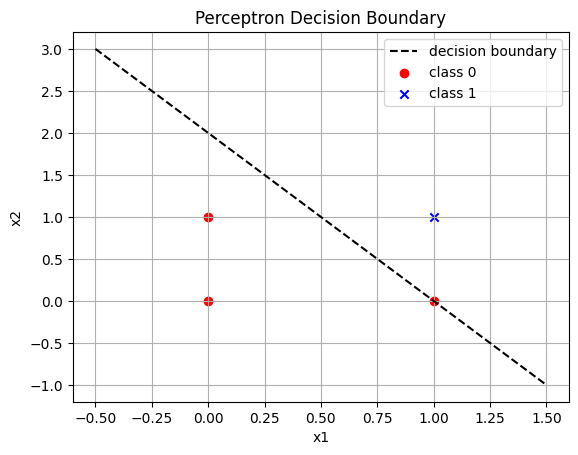

In [19]:
def plot_boundary(model, X, y):
    # decision boundary: w1*x1 + w2*x2 + b = 0
    # -> x2 = -(w1*x1 + b) / w2
    x1_vals = np.linspace(-0.5, 1.5, 100)
    x2_vals = -(model.weights[0] * x1_vals + model.bias) / model.weights[1]

    plt.plot(x1_vals, x2_vals, 'k--', label='decision boundary')
    plt.scatter(X[y==0][:,0], X[y==0][:,1], c='red',  marker='o', label='class 0')
    plt.scatter(X[y==1][:,0], X[y==1][:,1], c='blue', marker='x', label='class 1')
    plt.legend(); plt.xlabel('x1'); plt.ylabel('x2'); plt.title('Perceptron Decision Boundary')
    plt.grid(True); plt.show()

plot_boundary(model, X, y)

In [20]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])   # XOR

m = Perceptron(learning_rate=0.1, n_epochs=100)
m.fit(X_xor, y_xor)              # will NOT print "Converged"
print("accuracy:", (m.predict(X_xor) == y_xor).mean())

accuracy: 0.5


Load the dataset

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/campusx-official/100-days-of-deep-learning/refs/heads/main/day3/placement.csv')
df.head()

,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1


In [3]:
df.isnull().sum()

,0
cgpa,0
resume_score,0
placed,0


In [4]:
df.shape

(100, 3)

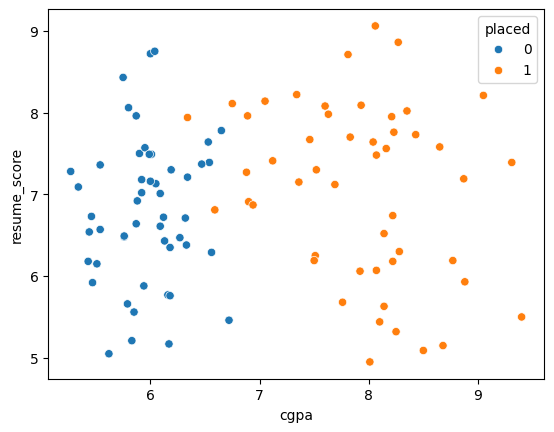

In [9]:
sns.scatterplot(df, x = 'cgpa', y = 'resume_score', hue = 'placed')
plt.show()

In [21]:
X = df.iloc[:, 0:2]
y = df.iloc[:, -1]

In [24]:
from sklearn.linear_model import Perceptron

perceptron = Perceptron()
perceptron.fit(X, y)

Perceptron()

In [26]:
print(f"bias: {perceptron.intercept_}")
print(f"weights: {perceptron.coef_}")

bias: [-25.]
weights: [[ 40.26 -36.  ]]


In [34]:
df.sample(5)

,cgpa,resume_score,placed
42,6.90,6.91,1
84,5.76,6.49,0
24,8.22,6.18,1
44,5.47,5.92,0
79,5.27,7.28,0


In [35]:
perceptron.predict(np.array([6.90, 	6.91]).reshape(1, -1))

array([1])

In [39]:
!pip install mlxtend

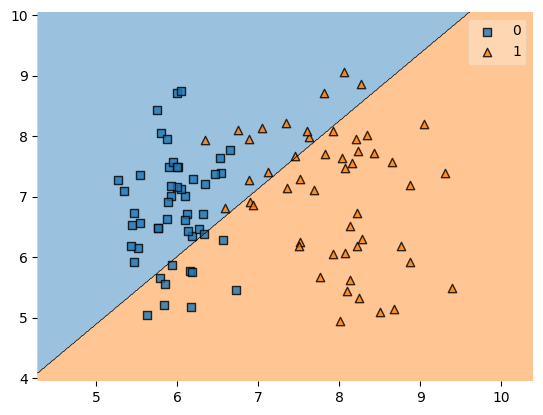

In [41]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X.values, y.values, perceptron)
plt.show()